
# EXPT NO: 2 — Comparative Study of Activation Functions and Optimization Algorithms in Deep Learning

**Course:** Deep Learning
**Experiment:** Comparative Study of Activation Functions and Optimization Algorithms  
**Student Roll No(s):** `24BAD069`  
**Name(s):** `Midhun P`  



In [1]:


ROLL_NO = "24BAD069"
NAME = "Midhun P"

print("Roll No(s):", ROLL_NO)
print("Name(s):", NAME)


Roll No(s): 24BAD069
Name(s): Midhun P


## 1. Setup and Dataset

In [2]:

# Install/import required libraries
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.20.0


In [3]:

# Reproducibility
SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Random seed set to:", SEED)


Random seed set to: 42


In [4]:

# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# Normalize pixel values to [0, 1]
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Create a validation set from the training data
x_val = x_train[-10000:]
y_val = y_train[-10000:]

x_train_sub = x_train[:-10000]
y_train_sub = y_train[:-10000]

print("Training set:", x_train_sub.shape, y_train_sub.shape)
print("Validation set:", x_val.shape, y_val.shape)
print("Test set:", x_test.shape, y_test.shape)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training set: (50000, 28, 28) (50000,)
Validation set: (10000, 28, 28) (10000,)
Test set: (10000, 28, 28) (10000,)



# TASK A — Visualization of Activation Functions

The lab requires visualization and comparison of:

- Sigmoid
- Tanh
- ReLU

The plots below use the same input range so that the three functions can be compared directly.


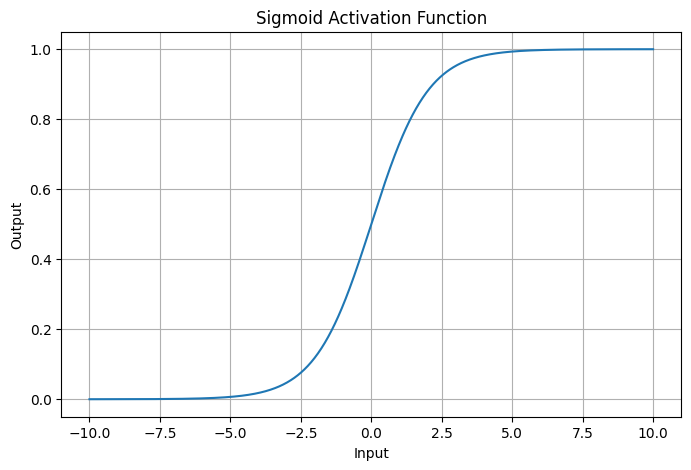

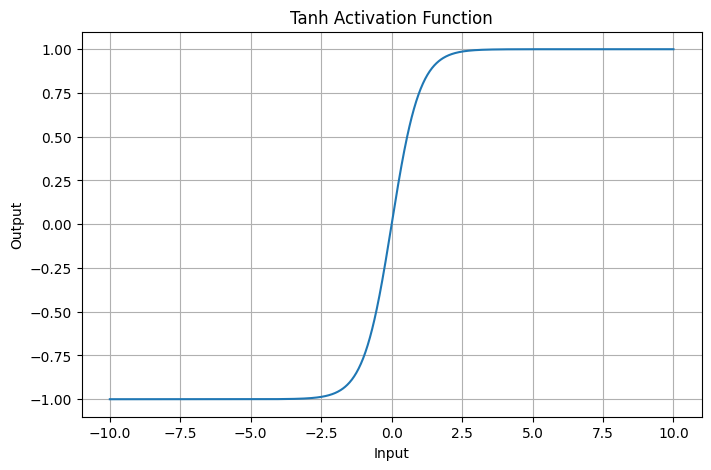

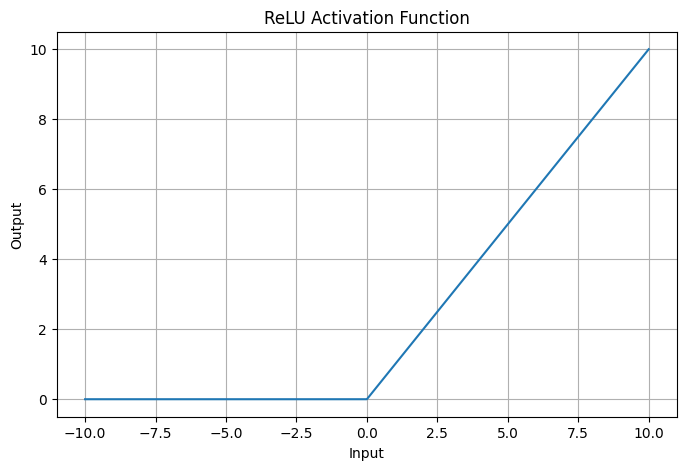

In [5]:

# Activation functions
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def tanh(x):
    return np.tanh(x)

def relu(x):
    return np.maximum(0, x)

x = np.linspace(-10, 10, 1000)

plt.figure(figsize=(8, 5))
plt.plot(x, sigmoid(x))
plt.title("Sigmoid Activation Function")
plt.xlabel("Input")
plt.ylabel("Output")
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(x, tanh(x))
plt.title("Tanh Activation Function")
plt.xlabel("Input")
plt.ylabel("Output")
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(x, relu(x))
plt.title("ReLU Activation Function")
plt.xlabel("Input")
plt.ylabel("Output")
plt.grid(True)
plt.show()


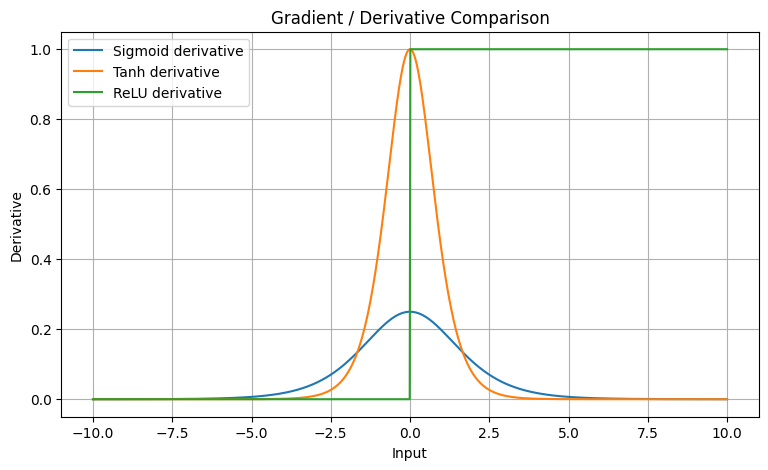

In [6]:

# Derivatives for gradient-behavior visualization
def sigmoid_derivative(x):
    s = sigmoid(x)
    return s * (1 - s)

def tanh_derivative(x):
    return 1 - np.tanh(x) ** 2

def relu_derivative(x):
    return (x > 0).astype(float)

plt.figure(figsize=(9, 5))
plt.plot(x, sigmoid_derivative(x), label="Sigmoid derivative")
plt.plot(x, tanh_derivative(x), label="Tanh derivative")
plt.plot(x, relu_derivative(x), label="ReLU derivative")
plt.title("Gradient / Derivative Comparison")
plt.xlabel("Input")
plt.ylabel("Derivative")
plt.legend()
plt.grid(True)
plt.show()



# TASK B — Performance Comparison of Activation Functions

We now train an identical ANN architecture using:

1. Sigmoid
2. Tanh
3. ReLU

Only the hidden-layer activation is changed. The dataset split, architecture, optimizer, batch size, and number of epochs are kept the same for a fair comparison.


In [7]:

# Common ANN settings for Task B
BATCH_SIZE = 128
EPOCHS = 15
LEARNING_RATE = 0.001

def build_activation_model(activation):
    model = keras.Sequential([
        layers.Input(shape=(28, 28)),
        layers.Flatten(),
        layers.Dense(128, activation=activation),
        layers.Dense(64, activation=activation),
        layers.Dense(10, activation="softmax")
    ])

    optimizer = keras.optimizers.Adam(learning_rate=LEARNING_RATE)

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

activation_models = {}
activation_histories = {}
activation_results = {}

for activation in ["sigmoid", "tanh", "relu"]:
    print(f"\nTraining model with {activation.upper()} activation...")

    tf.keras.backend.clear_session()
    tf.random.set_seed(SEED)

    model = build_activation_model(activation)

    history = model.fit(
        x_train_sub,
        y_train_sub,
        validation_data=(x_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        verbose=1
    )

    activation_models[activation] = model
    activation_histories[activation] = history

    final_train_loss = history.history["loss"][-1]
    final_val_loss = history.history["val_loss"][-1]
    final_train_acc = history.history["accuracy"][-1]
    final_val_acc = history.history["val_accuracy"][-1]

    activation_results[activation] = {
        "Final Training Loss": final_train_loss,
        "Final Validation Loss": final_val_loss,
        "Final Training Accuracy": final_train_acc,
        "Final Validation Accuracy": final_val_acc,
        "Epochs": len(history.history["loss"])
    }

activation_results_df = pd.DataFrame(activation_results).T
activation_results_df



Training model with SIGMOID activation...
Epoch 1/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8032 - loss: 0.8678 - val_accuracy: 0.9162 - val_loss: 0.3328
Epoch 2/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9201 - loss: 0.2942 - val_accuracy: 0.9343 - val_loss: 0.2297
Epoch 3/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9365 - loss: 0.2215 - val_accuracy: 0.9485 - val_loss: 0.1880
Epoch 4/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9477 - loss: 0.1806 - val_accuracy: 0.9542 - val_loss: 0.1624
Epoch 5/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9556 - loss: 0.1512 - val_accuracy: 0.9595 - val_loss: 0.1441
Epoch 6/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9625 - loss: 0.1285 - val_accuracy: 0.9622 - val_loss: 0.1299
Epoch 7/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9683 - loss: 0.1101 - val_accuracy: 0.9657 - val_loss: 0.1187
Epoch 8/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accurac

,Final Training Loss,Final Validation Loss,Final Training Accuracy,Final Validation Accuracy,Epochs
sigmoid,0.036086,0.082206,0.99116,0.9745,15.0
tanh,0.009161,0.101204,0.99810,0.9731,15.0
relu,0.012274,0.111959,0.99620,0.9759,15.0


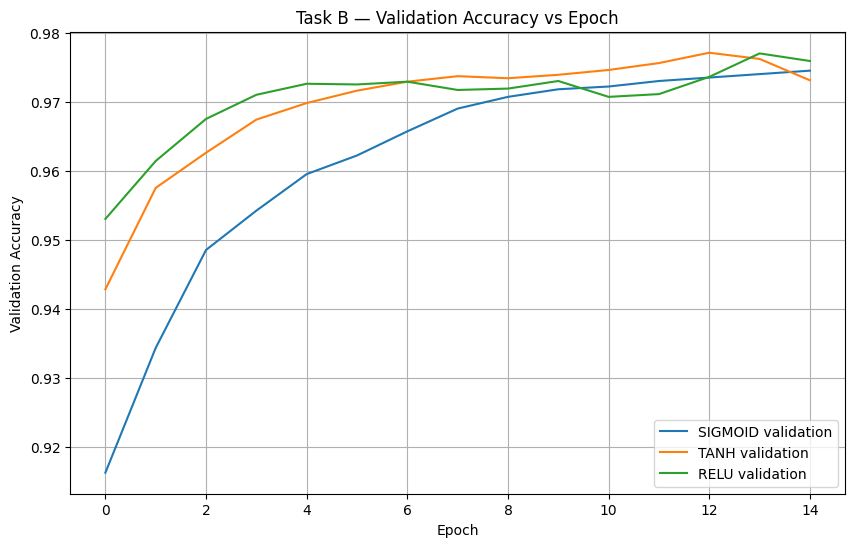

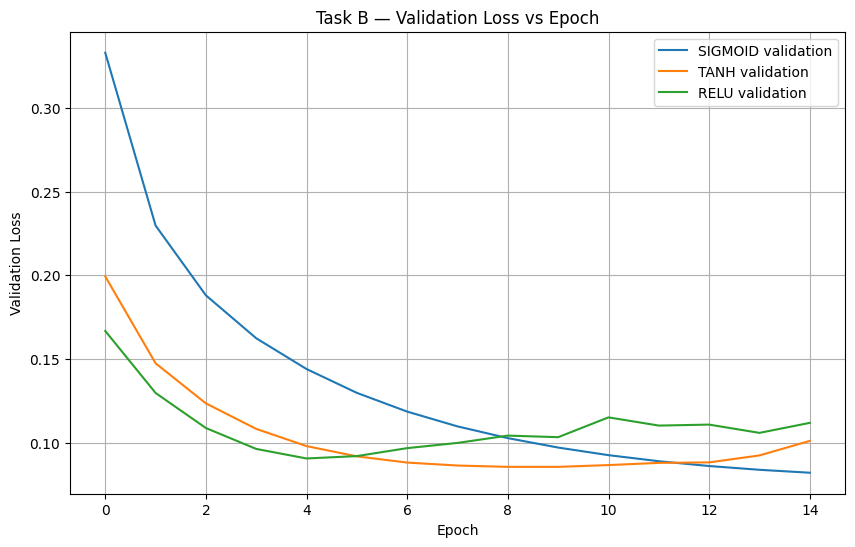

In [8]:

# Task B: Accuracy comparison
plt.figure(figsize=(10, 6))

for activation, history in activation_histories.items():
    plt.plot(history.history["val_accuracy"], label=f"{activation.upper()} validation")

plt.title("Task B — Validation Accuracy vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Task B: Loss comparison
plt.figure(figsize=(10, 6))

for activation, history in activation_histories.items():
    plt.plot(history.history["val_loss"], label=f"{activation.upper()} validation")

plt.title("Task B — Validation Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


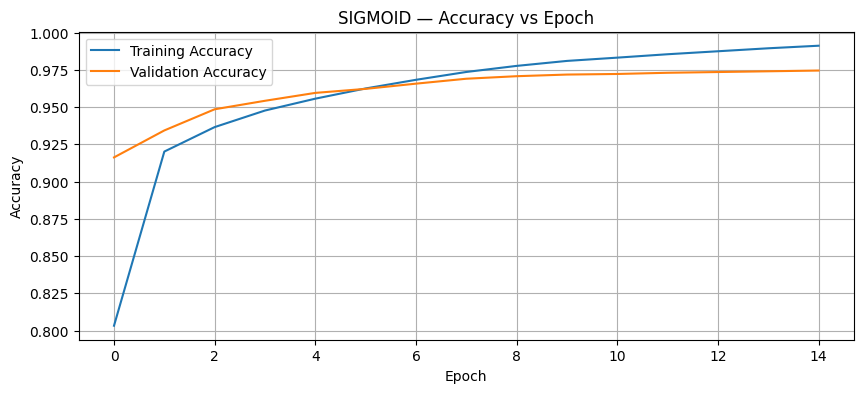

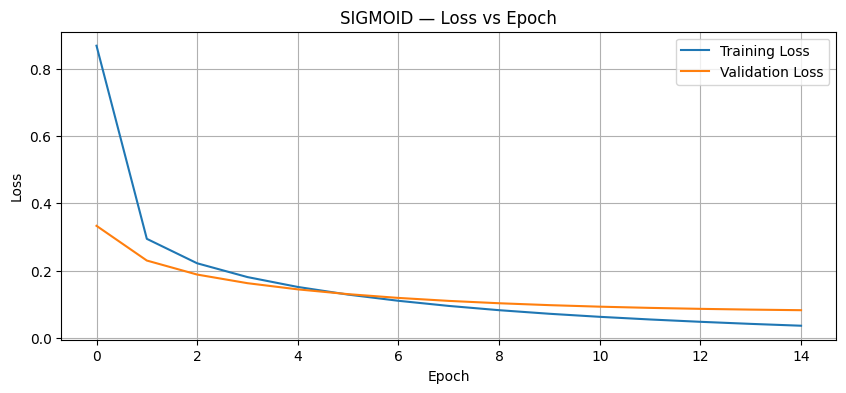

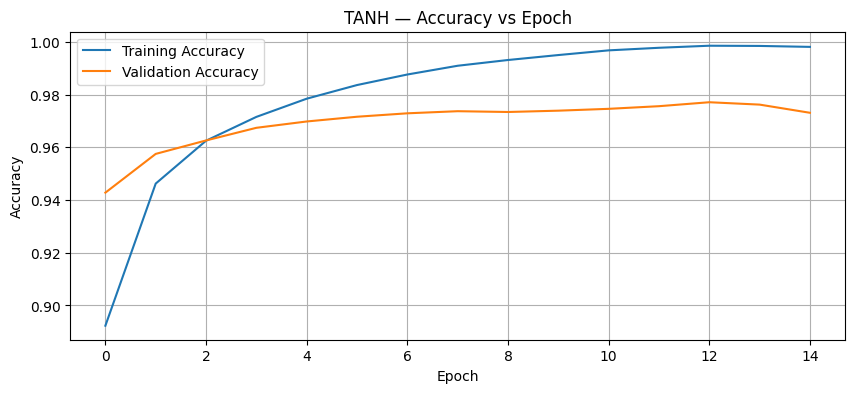

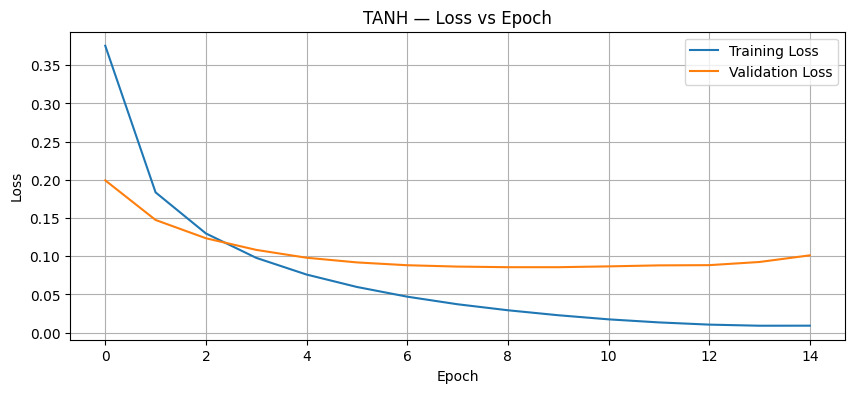

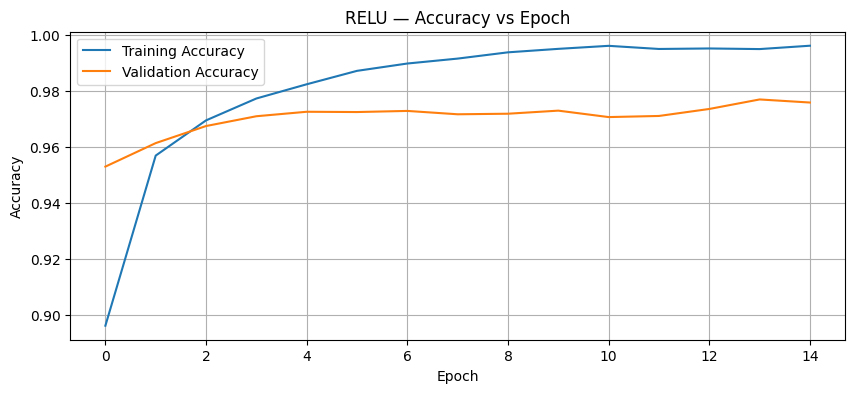

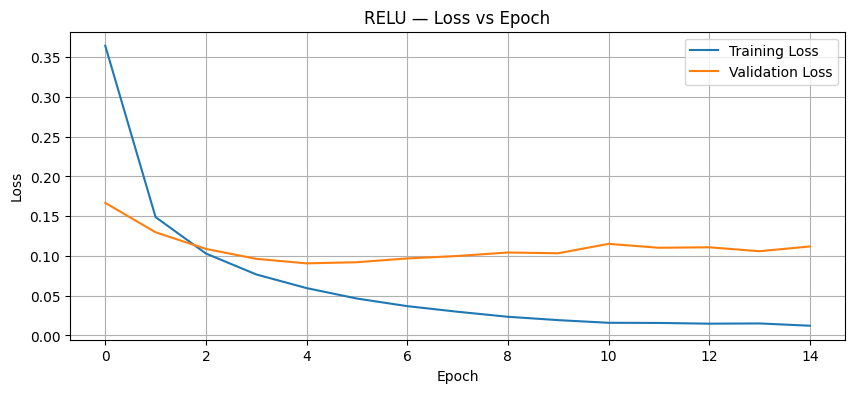

In [9]:

# Task B: Training and validation curves for each activation
for activation, history in activation_histories.items():
    fig = plt.figure(figsize=(10, 4))

    plt.plot(history.history["accuracy"], label="Training Accuracy")
    plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
    plt.title(f"{activation.upper()} — Accuracy vs Epoch")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)
    plt.show()

    fig = plt.figure(figsize=(10, 4))

    plt.plot(history.history["loss"], label="Training Loss")
    plt.plot(history.history["val_loss"], label="Validation Loss")
    plt.title(f"{activation.upper()} — Loss vs Epoch")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.show()


In [10]:

# Identify the activation with the highest final validation accuracy
best_activation = activation_results_df["Final Validation Accuracy"].idxmax()

print("Best activation based on final validation accuracy:", best_activation.upper())
print(
    "Final validation accuracy:",
    round(activation_results_df.loc[best_activation, "Final Validation Accuracy"] * 100, 2),
    "%"
)


Best activation based on final validation accuracy: RELU
Final validation accuracy: 97.59 %



# TASK C — Comparison of Optimization Algorithms

The lab requires comparison of:

- SGD
- Momentum
- RMSProp
- Adam

The ANN architecture is kept identical. ReLU is used as the hidden-layer activation for this optimizer comparison, while only the optimizer is changed.


In [11]:

# Common settings for Task C
OPT_EPOCHS = 15
OPT_BATCH_SIZE = 128
OPT_LEARNING_RATE = 0.001

def build_optimizer_model(optimizer_name):
    model = keras.Sequential([
        layers.Input(shape=(28, 28)),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(64, activation="relu"),
        layers.Dense(10, activation="softmax")
    ])

    if optimizer_name == "SGD":
        optimizer = keras.optimizers.SGD(learning_rate=0.01)
    elif optimizer_name == "Momentum":
        optimizer = keras.optimizers.SGD(
            learning_rate=0.01,
            momentum=0.9
        )
    elif optimizer_name == "RMSProp":
        optimizer = keras.optimizers.RMSprop(
            learning_rate=OPT_LEARNING_RATE
        )
    elif optimizer_name == "Adam":
        optimizer = keras.optimizers.Adam(
            learning_rate=OPT_LEARNING_RATE
        )
    else:
        raise ValueError("Unknown optimizer")

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


In [12]:

# Train all four optimizer variants
optimizer_models = {}
optimizer_histories = {}
optimizer_results = {}

for optimizer_name in ["SGD", "Momentum", "RMSProp", "Adam"]:
    print(f"\nTraining with {optimizer_name}...")

    tf.keras.backend.clear_session()
    tf.random.set_seed(SEED)

    model = build_optimizer_model(optimizer_name)

    history = model.fit(
        x_train_sub,
        y_train_sub,
        validation_data=(x_val, y_val),
        epochs=OPT_EPOCHS,
        batch_size=OPT_BATCH_SIZE,
        verbose=1
    )

    optimizer_models[optimizer_name] = model
    optimizer_histories[optimizer_name] = history

    optimizer_results[optimizer_name] = {
        "Final Training Loss": history.history["loss"][-1],
        "Final Validation Loss": history.history["val_loss"][-1],
        "Final Training Accuracy": history.history["accuracy"][-1],
        "Final Validation Accuracy": history.history["val_accuracy"][-1],
        "Epochs": len(history.history["loss"])
    }

optimizer_results_df = pd.DataFrame(optimizer_results).T
optimizer_results_df



Training with SGD...
Epoch 1/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6314 - loss: 1.4056 - val_accuracy: 0.8496 - val_loss: 0.7016
Epoch 2/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8553 - loss: 0.5726 - val_accuracy: 0.8894 - val_loss: 0.4282
Epoch 3/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8835 - loss: 0.4242 - val_accuracy: 0.9044 - val_loss: 0.3543
Epoch 4/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8969 - loss: 0.3683 - val_accuracy: 0.9119 - val_loss: 0.3194
Epoch 5/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9046 - loss: 0.3366 - val_accuracy: 0.9169 - val_loss: 0.2978
Epoch 6/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9105 - loss: 0.3147 - val_accuracy: 0.9200 - val_loss: 0.2821
Epoch 7/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9149 - loss: 0.2978 - val_accuracy: 0.9229 - val_loss: 0.2696
Epoch 8/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9187 - loss: 0.2

,Final Training Loss,Final Validation Loss,Final Training Accuracy,Final Validation Accuracy,Epochs
SGD,0.222483,0.210890,0.93676,0.9411,15.0
Momentum,0.036356,0.084975,0.99112,0.9760,15.0
RMSProp,0.007983,0.118562,0.99800,0.9761,15.0
Adam,0.014091,0.108025,0.99550,0.9758,15.0


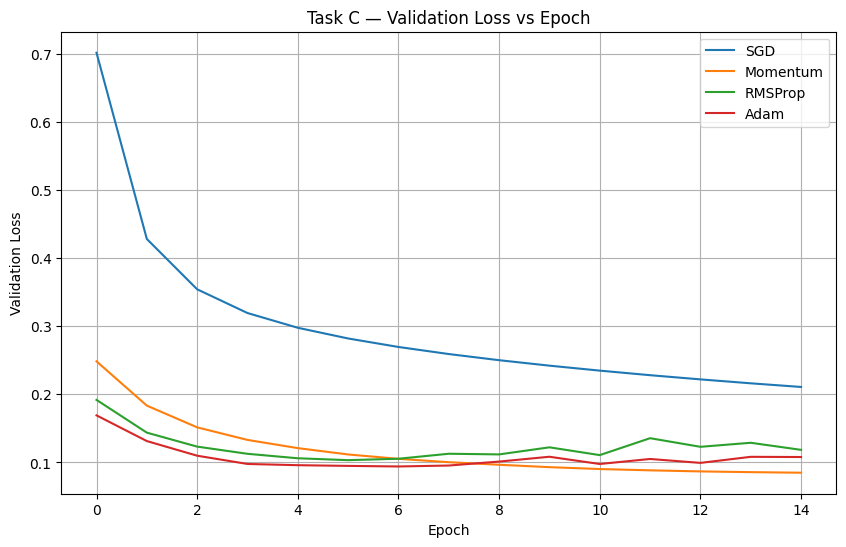

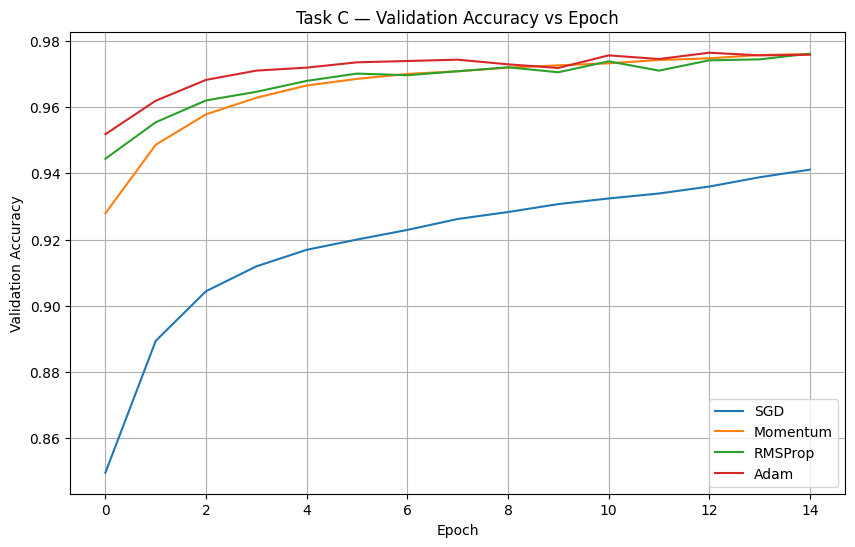

In [13]:

# Task C: Loss vs Epoch
plt.figure(figsize=(10, 6))

for optimizer_name, history in optimizer_histories.items():
    plt.plot(history.history["val_loss"], label=optimizer_name)

plt.title("Task C — Validation Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

# Task C: Accuracy vs Epoch
plt.figure(figsize=(10, 6))

for optimizer_name, history in optimizer_histories.items():
    plt.plot(history.history["val_accuracy"], label=optimizer_name)

plt.title("Task C — Validation Accuracy vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()


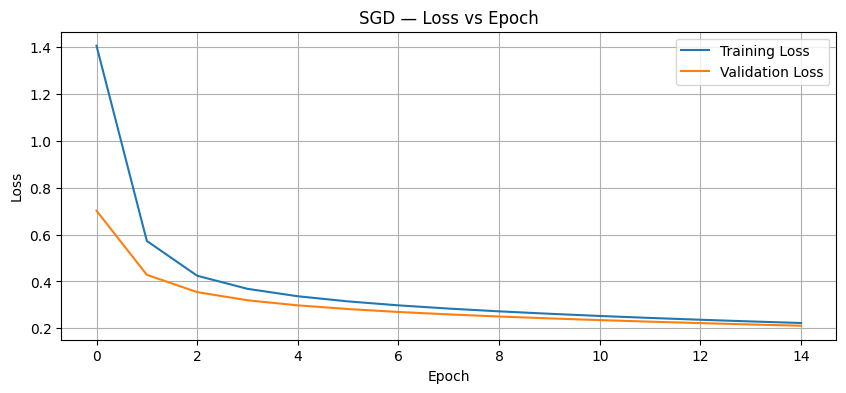

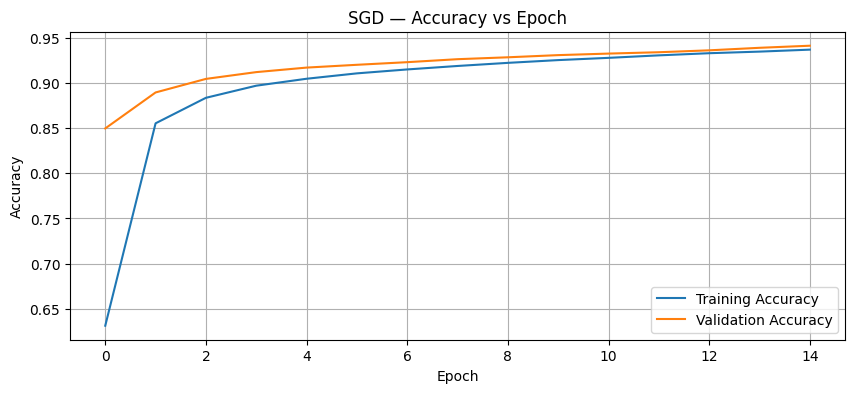

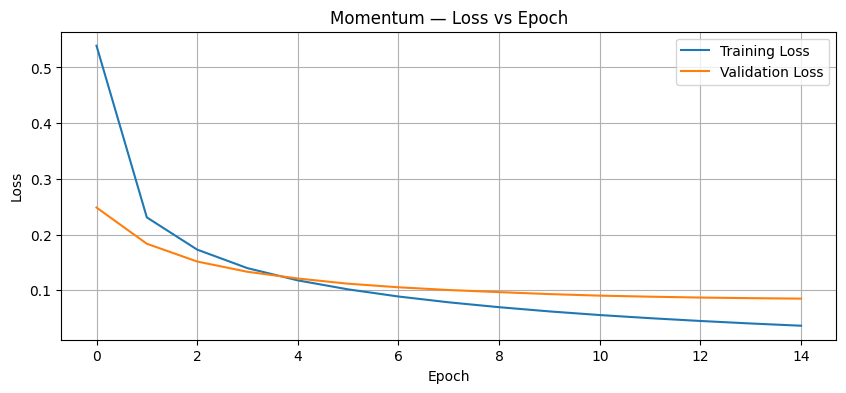

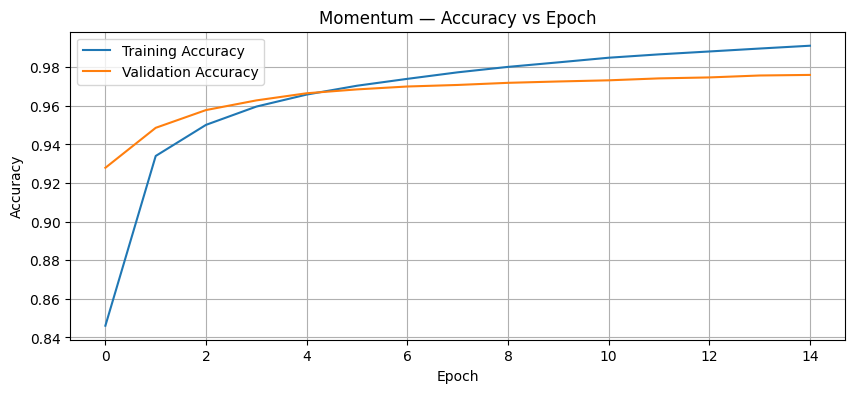

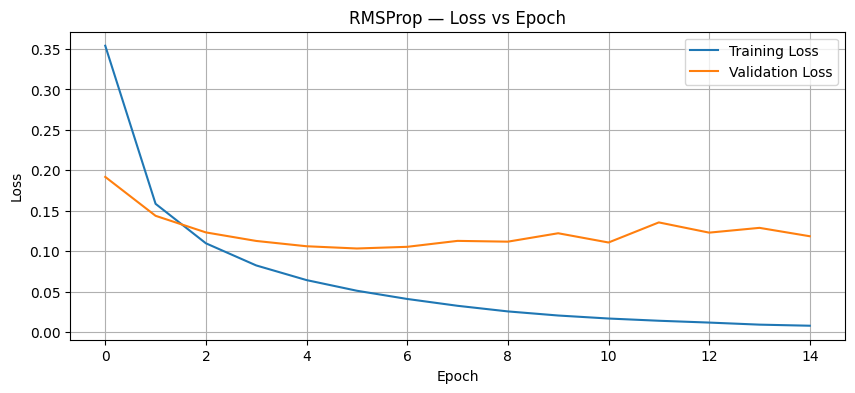

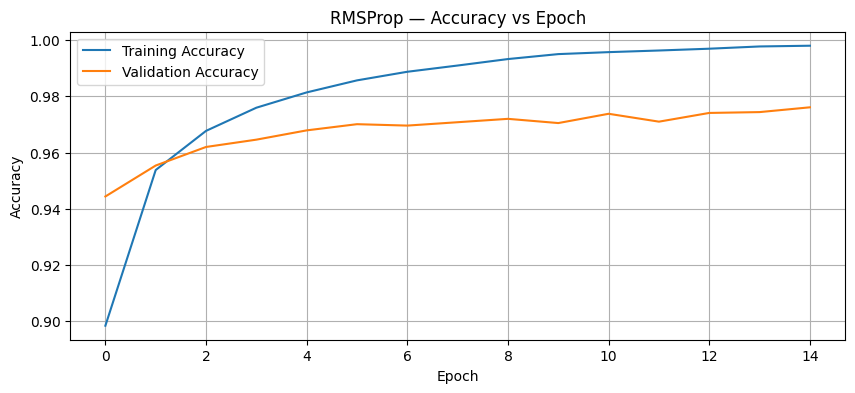

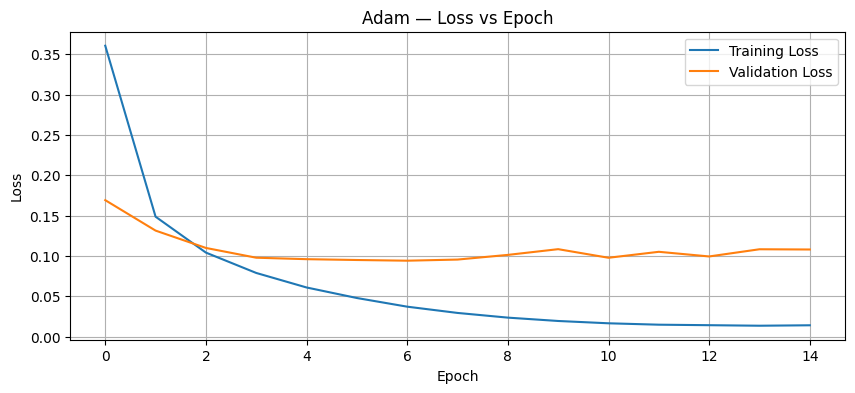

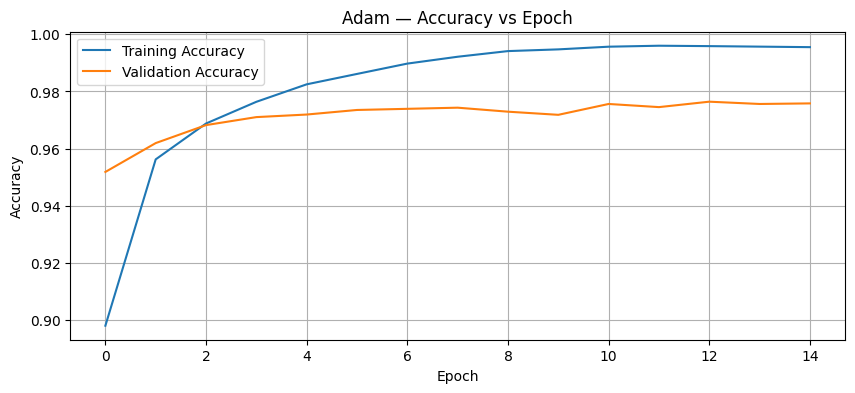

In [14]:

# Detailed training curves for each optimizer
for optimizer_name, history in optimizer_histories.items():
    plt.figure(figsize=(10, 4))
    plt.plot(history.history["loss"], label="Training Loss")
    plt.plot(history.history["val_loss"], label="Validation Loss")
    plt.title(f"{optimizer_name} — Loss vs Epoch")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.show()

    plt.figure(figsize=(10, 4))
    plt.plot(history.history["accuracy"], label="Training Accuracy")
    plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
    plt.title(f"{optimizer_name} — Accuracy vs Epoch")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)
    plt.show()


In [15]:

# Identify the optimizer with the best final validation accuracy
best_optimizer = optimizer_results_df["Final Validation Accuracy"].idxmax()

print("Best optimizer based on final validation accuracy:", best_optimizer)
print(
    "Final validation accuracy:",
    round(optimizer_results_df.loc[best_optimizer, "Final Validation Accuracy"] * 100, 2),
    "%"
)

print("\nOptimizer comparison:")
display(optimizer_results_df.round(4))


Best optimizer based on final validation accuracy: RMSProp
Final validation accuracy: 97.61 %

Optimizer comparison:


,Final Training Loss,Final Validation Loss,Final Training Accuracy,Final Validation Accuracy,Epochs
SGD,0.2225,0.2109,0.9368,0.9411,15.0
Momentum,0.0364,0.0850,0.9911,0.9760,15.0
RMSProp,0.0080,0.1186,0.9980,0.9761,15.0
Adam,0.0141,0.1080,0.9955,0.9758,15.0



# TASK D — Deep Learning Experiment Management

The lab asks you to:

- Create a Google Colab notebook.
- Mount Google Drive.
- Save notebooks and trained models.
- Create a GitHub repository.
- Upload the notebook.
- Commit changes and maintain version history.
- Document the experiment using `README.md`.



In [17]:
import os

# Google Drive mounting
try:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=True) # Added force_remount for robustness
    print("Google Drive mounted successfully.")
except Exception as e: # Catching a more general Exception to cover MessageError
    print("Failed to mount Google Drive.")
    print("Please re-run this cell and follow the prompts to authorize Google Drive access.")
    print(f"Details: {e}")

Mounted at /content/drive
Google Drive mounted successfully.


In [18]:

# Save experiment models/results to Google Drive

DRIVE_DIR = "/content/drive/MyDrive/EXPT_NO_2_DEEP_LEARNING"

try:
    os.makedirs(DRIVE_DIR, exist_ok=True)

    # Save activation models
    for activation, model in activation_models.items():
        model.save(os.path.join(DRIVE_DIR, f"activation_{activation}.keras"))

    # Save optimizer models
    for optimizer_name, model in optimizer_models.items():
        safe_name = optimizer_name.lower().replace(" ", "_")
        model.save(os.path.join(DRIVE_DIR, f"optimizer_{safe_name}.keras"))

    # Save result tables
    activation_results_df.to_csv(
        os.path.join(DRIVE_DIR, "activation_results.csv")
    )

    optimizer_results_df.to_csv(
        os.path.join(DRIVE_DIR, "optimizer_results.csv")
    )

    print("Models and result tables saved to:", DRIVE_DIR)

except Exception as e:
    print("Save step could not be completed.")
    print("If using Colab, run the Google Drive mounting cell first.")
    print("Details:", e)


Models and result tables saved to: /content/drive/MyDrive/EXPT_NO_2_DEEP_LEARNING
